Name : Mohammad Ayaan Khan

USC ID : 4147952900

Email : mkhan736@usc.edu

GitHub username : MohammadAyaanKhan

# Homework 5: Decision Trees, LASSO, PCR and Boosting

**Datasets** (both stored in `../data/`, downloaded from UCI automatically if missing):
- Acute Inflammations (https://archive.ics.uci.edu/dataset/184/acute+inflammations)
- Communities and Crime (https://archive.ics.uci.edu/dataset/183/communities+and+crime)

All random processes use the seed 552 so the results are reproducible.

In [1]:
# Imports
import os, io, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text, _tree
from sklearn.model_selection import (cross_val_score, RepeatedStratifiedKFold, KFold, GridSearchCV)
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.metrics import mean_squared_error, r2_score
import xgboost as xgb
pd.set_option('display.width', 140)
pd.set_option('display.max_columns', 30)
sns.set_theme(style='whitegrid')
SEED = 552
DATA_DIR = '../data'
os.makedirs(DATA_DIR, exist_ok=True)
def fetch_uci(zip_url, members):
    # Download a UCI zip once and extract only the files we need into DATA_DIR
    if all(os.path.exists(os.path.join(DATA_DIR, m)) for m in members):
        return
    z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(zip_url).read()))
    for m in members:
        with open(os.path.join(DATA_DIR, m), 'wb') as f:
            f.write(z.read(m))
def print_columns(s, ncols=3, fmt='{:.4f}'):
    # Print a long list of (name, value) pairs in side-by-side columns so the output stays short
    items = [f'{k:<22s}{fmt.format(v):>9s}' for k, v in s.items()]
    nrows = int(np.ceil(len(items) / ncols))
    for r in range(nrows):
        print('   '.join(items[r + c * nrows] for c in range(ncols) if r + c * nrows < len(items)))
print('xgboost', xgb.__version__)

xgboost 3.4.1


# 1. Decision Trees as Interpretable Models

## 1(a) Download the Acute Inflammations data

In [2]:
fetch_uci('https://archive.ics.uci.edu/static/public/184/acute+inflammations.zip',
          ['diagnosis.data', 'diagnosis.names'])
# The file is UTF-16 encoded, tab separated, and uses a decimal comma for temperature (e.g. "35,5")
cols = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
        'burning_urethra', 'inflammation_bladder', 'nephritis']
with open(os.path.join(DATA_DIR, 'diagnosis.data'), 'rb') as f:
    text = f.read().decode('utf-16')
ai = pd.read_csv(io.StringIO(text), sep='\t', header=None, names=cols)
ai['temperature'] = ai['temperature'].str.replace(',', '.').astype(float)
for c in cols[1:]:
    ai[c] = ai[c].str.strip().map({'no': 0, 'yes': 1})
print('Shape:', ai.shape)
print('Missing values:', int(ai.isna().sum().sum()))
ai.head()

Shape: (120, 8)
Missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation_bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


**Variables.** **temperature** is the name of the feature denoting the patient’s body temperature in degrees Celsius, varying between 35.5 and 41.5. The next five features are binary features (1/0) denoting the presence of the following symptoms: **nausea**, **lumbar_pain** (lumbar pain), **urine_pushing** (a continuous need to urinate), **micturition_pains** (pain during urination), and **burning_urethra** (burning of the urethra, including itching and swelling of the urethral opening). The two target labels, each encoded 1/0, are inflammation_bladder (inflammation of the urinary bladder) and nephritis (nephritis of renal pelvis origin).

## 1(b) Build a decision tree on the whole data set and plot it

**Handling the two labels.** Since each patient has two labels, this is a multi-label problem. The **label powerset** technique creates a class from each possible combination of the two labels, so there can be no more than
$2^2 = 4$ classes. The **binary relevance** technique creates an independent tree for each label.

**Impurity.**
At each node, the tree chooses the split that minimizes the weighted Gini impurity $G = 1 - \sum_k p_k^2$ of the two child nodes, where $p_k$ is the proportion of samples belonging to the class $k$ in the node. The Gini impurity equals zero if the node contains a single class. This value is shown in each box of the tree diagram.

In [3]:
# Inputs: the temperature and the five yes/no symptoms (the first six columns)
features = cols[:6]
# Outputs: the two diagnosis labels
labels = ['inflammation_bladder', 'nephritis']
X_ai = ai[features]
# Label powerset: one class for each combination of the two labels
lp_names = {(0, 0): 'neither', (1, 0): 'bladder only', (0, 1): 'nephritis only', (1, 1): 'both'}
y_lp = ai[labels].apply(lambda r: lp_names[(r.iloc[0], r.iloc[1])], axis=1)
print('Label-powerset class counts:')
print(y_lp.value_counts().to_string())

Label-powerset class counts:
bladder only      40
nephritis only    31
neither           30
both              19


Training accuracy: 1.0
Depth: 4  Leaves: 6


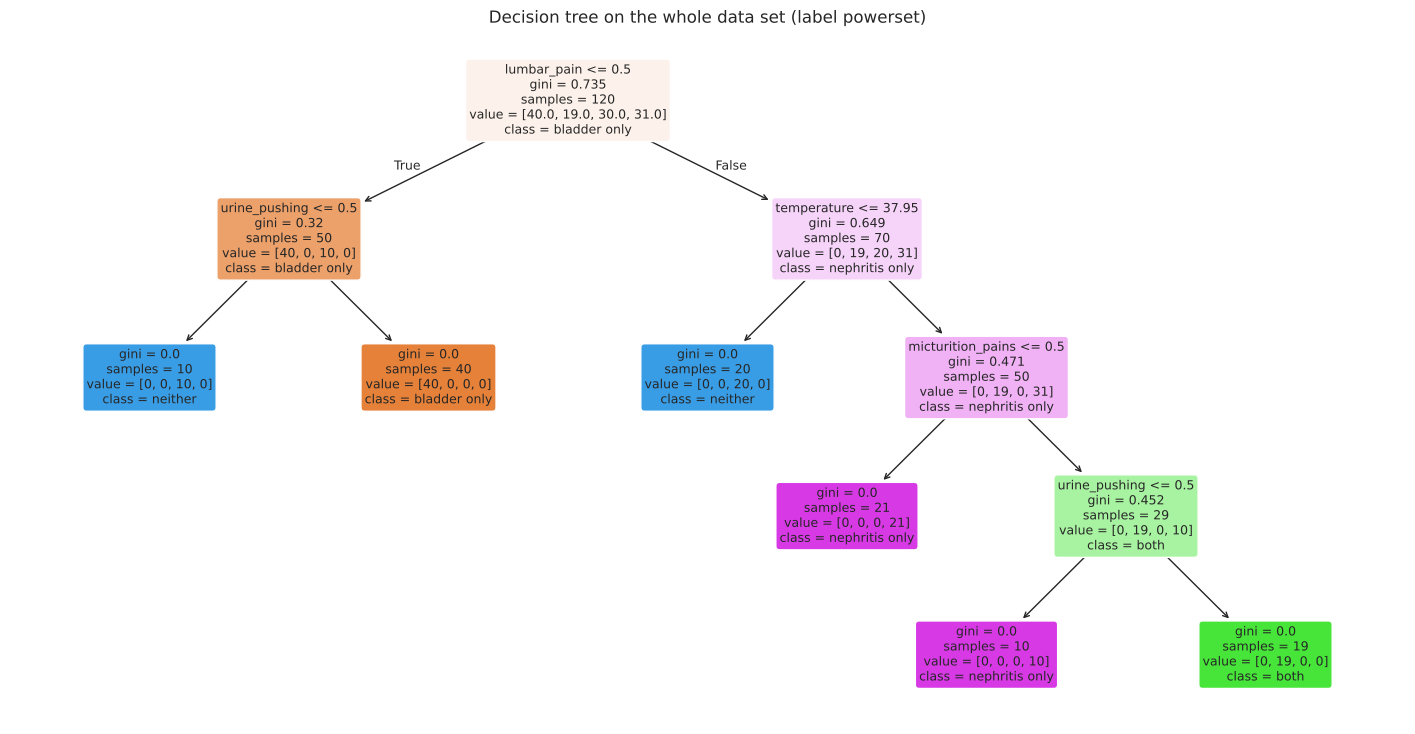

In [4]:
# Decision tree on the whole data set (label powerset target)
tree_full = DecisionTreeClassifier(random_state=SEED).fit(X_ai, y_lp)
print('Training accuracy:', tree_full.score(X_ai, y_lp))
print('Depth:', tree_full.get_depth(), ' Leaves:', tree_full.get_n_leaves())
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(tree_full, feature_names=features, class_names=list(tree_full.classes_),
          filled=True, rounded=True, impurity=True, fontsize=9, ax=ax)
ax.set_title('Decision tree on the whole data set (label powerset)')
plt.show()

In [5]:
# For comparison: binary relevance, one tree per label
for lab in labels:
    t = DecisionTreeClassifier(random_state=SEED).fit(X_ai, ai[lab])
    print(f'{lab:22s} accuracy = {t.score(X_ai, ai[lab]):.3f}  depth = {t.get_depth()}  leaves = {t.get_n_leaves()}')
print(f"{'label powerset':22s} accuracy = {tree_full.score(X_ai, y_lp):.3f}  depth = {tree_full.get_depth()}  leaves = {tree_full.get_n_leaves()}")

inflammation_bladder   accuracy = 1.000  depth = 3  leaves = 4
nephritis              accuracy = 1.000  depth = 2  leaves = 3
label powerset         accuracy = 1.000  depth = 4  leaves = 6


**Answer to footnote 1 (is label powerset more relevant?).** Yes. I used the label powerset method for the tree, because:
1. There are only 2 labels, so only $2^2 = 4$ classes, and each class occurs sufficiently often (19 to 40 patients). The usual limitation of the label powerset method, too many rare label sets, doesn’t hold here.
2. These two diseases occur simultaneously, i.e., 19 people have both diseases. The label powerset can model this co-occurrence, while the binary relevance approach treats the two labels independently.
3. One tree gives one set of rules for the whole diagnosis, which suits the goal of an interpretable model.

The binary relevance approach is a valid alternative for classification, since its 2 trees also perfectly fit the data (4 and 3 leaves; total 7 leaves vs. 6 leaves of the label-powerset tree).

**The tree.** The label-powerset tree perfectly classifies all 120 patients with a depth of 4 and 6 leaves. The root split is on lumbar pain, temperature is the only continuous feature used (threshold 37.95 °C), and `nausea` and `burning_urethra` aren’t used.

## 1(c) Convert the decision rules into a set of IF-THEN rules

In [6]:
# Walk the fitted tree (t = model.tree_) from the root node to each leaf, collecting the split conditions on the path (conds, with threshold thr.
# yes/no symptoms shown as "= yes/no") into one IF-THEN rule per leaf, with its predicted class (cls) and number of patients (n).
binary_feats = set(features[1:])
def condition(name, threshold, go_left):
    # Binary features are split at 0.5, so print them as "= no" / "= yes" for readability
    if name in binary_feats:
        return f"{name} = {'no' if go_left else 'yes'}"
    return f"{name} {'<=' if go_left else '>'} {threshold:.2f}"
def tree_to_rules(model, feature_names):
    t = model.tree_
    rules = []
    def recurse(node, conds):
        if t.feature[node] != _tree.TREE_UNDEFINED:
            name, thr = feature_names[t.feature[node]], t.threshold[node]
            recurse(t.children_left[node], conds + [condition(name, thr, True)])
            recurse(t.children_right[node], conds + [condition(name, thr, False)])
        else:
            counts = t.value[node][0]
            cls = model.classes_[np.argmax(counts)]
            n = int(t.n_node_samples[node])
            rules.append((conds, cls, n))
    recurse(0, [])
    return rules
def print_rules(model, feature_names):
    for i, (conds, cls, n) in enumerate(tree_to_rules(model, feature_names), 1):
        print(f"Rule {i}: IF " + ' AND '.join(conds) + f"\n         THEN diagnosis = {cls}   ({n} patients)")

print_rules(tree_full, features)

Rule 1: IF lumbar_pain = no AND urine_pushing = no
         THEN diagnosis = neither   (10 patients)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
         THEN diagnosis = bladder only   (40 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
         THEN diagnosis = neither   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
         THEN diagnosis = nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
         THEN diagnosis = nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
         THEN diagnosis = both   (19 patients)


## 1(d) Cost-complexity pruning

Cost complexity pruning minimizes $R_\alpha(T) = R(T) + \alpha\,|T|$, where $R(T)$ is the sum of Gini impurities of leaves, each weighted by the fraction of patients contained in it, and $|T|$ is the number of leaves. For every value of $\alpha$ along the pruning path, there is a subtree, and higher values of $\alpha$ produce smaller trees. $\alpha$ is selected using repeated stratified 5-fold cross-validation (10 runs). In *stratified* folds, every class is represented proportionally to its frequency in every fold. Running the split 10 times with different shuffles will give a more robust estimate of accuracy on just 120 patients. The next step is applying the **one-standard-error rule**: pick the largest $\alpha$ (smallest tree) whose mean cross-validation accuracy is within one standard error of the maximum.

In [7]:
# For each alpha in alphas (from the pruning path), fit a tree m and score it with repeated stratified 5-fold CV (cv; s = fold accuracies);
path = tree_full.cost_complexity_pruning_path(X_ai, y_lp)
alphas = np.unique(path.ccp_alphas)
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
rows = []
for a in alphas:
    m = DecisionTreeClassifier(random_state=SEED, ccp_alpha=a)
    s = cross_val_score(m, X_ai, y_lp, cv=cv, scoring='accuracy')
    leaves = m.fit(X_ai, y_lp).get_n_leaves()
    rows.append({'ccp_alpha': a, 'leaves': leaves, 'cv_accuracy': s.mean(), 'cv_se': s.std(ddof=1) / np.sqrt(len(s))})
prune = pd.DataFrame(rows)#prune = table of leaves, mean accuracy and SE
display(prune.round(4))
best = prune['cv_accuracy'].idxmax()#best = top-accuracy row
threshold = prune.loc[best, 'cv_accuracy'] - prune.loc[best, 'cv_se']# threshold = its accuracy minus one SE
chosen = prune[prune['cv_accuracy'] >= threshold]['ccp_alpha'].max()#chosen = largest alpha above threshold.
print(f"Best CV accuracy = {prune.loc[best, 'cv_accuracy']:.4f} (alpha = {prune.loc[best, 'ccp_alpha']:.4f})")
print(f'One-SE threshold = {threshold:.4f}  ->  chosen alpha = {chosen:.4f}')

,ccp_alpha,leaves,cv_accuracy,cv_se
0,0.0000,6,0.9892,0.0031
1,0.0982,4,0.8492,0.0087
2,0.1333,3,0.7583,0.0079
3,0.1820,2,0.6758,0.0093
4,0.2229,1,0.4900,0.0176


Best CV accuracy = 0.9892 (alpha = 0.0000)
One-SE threshold = 0.9861  ->  chosen alpha = 0.0000


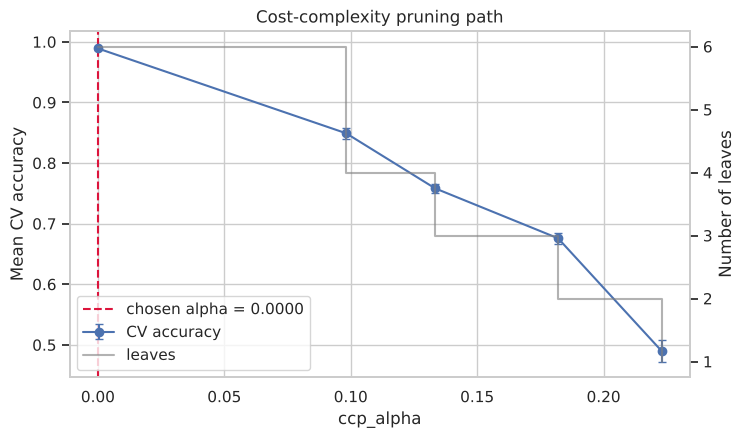

In [8]:
fig, ax1 = plt.subplots(figsize=(8, 4.5))
ax1.errorbar(prune['ccp_alpha'], prune['cv_accuracy'], yerr=prune['cv_se'], marker='o', capsize=3, label='CV accuracy')
ax1.axvline(chosen, color='crimson', ls='--', label=f'chosen alpha = {chosen:.4f}')
ax1.set_xlabel('ccp_alpha'); ax1.set_ylabel('Mean CV accuracy')
ax2 = ax1.twinx()
ax2.step(prune['ccp_alpha'], prune['leaves'], where='post', color='grey', alpha=0.6, label='leaves')
ax2.set_ylabel('Number of leaves')
ax2.grid(False)
h1, l1 = ax1.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='lower left')
ax1.set_title('Cost-complexity pruning path')
plt.show()

Pruned tree: training accuracy = 1.0  depth = 4  leaves = 6


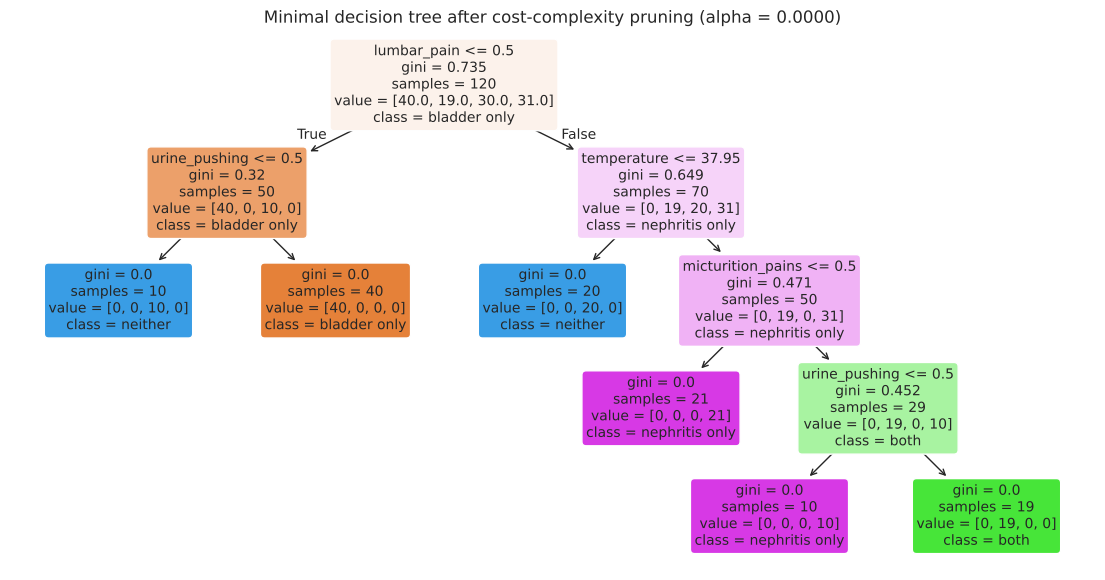


IF-THEN rules of the pruned tree:
Rule 1: IF lumbar_pain = no AND urine_pushing = no
         THEN diagnosis = neither   (10 patients)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes
         THEN diagnosis = bladder only   (40 patients)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95
         THEN diagnosis = neither   (20 patients)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = no
         THEN diagnosis = nephritis only   (21 patients)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = no
         THEN diagnosis = nephritis only   (10 patients)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND micturition_pains = yes AND urine_pushing = yes
         THEN diagnosis = both   (19 patients)


In [9]:
# Refit the tree on all patients with the chosen alpha (tree_pruned), report its accuracy, depth and leaves, plot it, and print its IF-THEN rules.
tree_pruned = DecisionTreeClassifier(random_state=SEED, ccp_alpha=chosen).fit(X_ai, y_lp)
print('Pruned tree: training accuracy =', round(tree_pruned.score(X_ai, y_lp), 4),
      ' depth =', tree_pruned.get_depth(), ' leaves =', tree_pruned.get_n_leaves())
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(tree_pruned, feature_names=features, class_names=list(tree_pruned.classes_),
          filled=True, rounded=True, fontsize=10, ax=ax)
ax.set_title(f'Minimal decision tree after cost-complexity pruning (alpha = {chosen:.4f})')
plt.show()
print('\nIF-THEN rules of the pruned tree:')
print_rules(tree_pruned, features)

**Result.** The one-standard-error rule chooses $\alpha = 0$, so the minimal tree coincides with the original unpruned tree, and its number of leaves equals 6. Moreover, the mean CV accuracy of the minimal tree equals 98.9%. Any larger α on the pruning path removes a split that is necessary for the diagnosis. For example, the second largest tree (with 4 leaves) has the CV accuracy equal to 84.9%, while the 1-leaf tree has 49.0%. Our dataset is perfectly separable, thus our complete tree has no unnecessary splits related to noise.

**Interpretable rule set.** The 6 rules written above correspond to decision rules of our minimal tree. The rules 4 and 5 have identical conclusions, hence they may be combined into one rule. Reading the tree one label at a time gives an even more compact set of two rules, which the next cell checks against every patient:
- **Nephritis of renal pelvis origin**: IF lumbar pain = yes AND temperature > 37.95 °C.
- **Inflammation of the urinary bladder**: IF urine pushing = yes AND (lumbar pain = no OR micturition pains = yes).

A patient has both diseases when both rules apply, only one disease when only that rule applies, and neither when neither rule applies.

In [10]:
# Check the compact per-label rules read off the pruned tree against every patient
nephritis_rule = (ai['lumbar_pain'] == 1) & (ai['temperature'] > 37.95)
bladder_rule = (ai['urine_pushing'] == 1) & ((ai['lumbar_pain'] == 0) | (ai['micturition_pains'] == 1))
print('Nephritis rule accuracy:           ', (nephritis_rule.astype(int) == ai['nephritis']).mean())
print('Bladder inflammation rule accuracy:', (bladder_rule.astype(int) == ai['inflammation_bladder']).mean())

Nephritis rule accuracy:            1.0
Bladder inflammation rule accuracy: 1.0


# 2. The LASSO and Boosting for Regression

## 2(a) Download the Communities and Crime data; first 1495 rows for training

In [11]:
fetch_uci('https://archive.ics.uci.edu/static/public/183/communities+and+crime.zip',
          ['communities.data', 'communities.names'])
# Column names come from the @attribute lines of communities.names
with open(os.path.join(DATA_DIR, 'communities.names'), encoding='latin-1') as f:
    names = [ln.split()[1] for ln in f if ln.startswith('@attribute')]
cc = pd.read_csv(os.path.join(DATA_DIR, 'communities.data'), header=None, names=names, na_values='?')
print('Shape:', cc.shape)
cc.head()

Shape: (1994, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,racePctHisp,agePct12t21,agePct12t29,agePct16t24,agePct65up,...,PctPolicAsian,PctPolicMinor,OfficAssgnDrugUnits,NumKindsDrugsSeiz,PolicAveOTWorked,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,0.17,0.34,0.47,0.29,0.32,...,0.1,0.07,0.02,0.57,0.29,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,0.07,0.26,0.59,0.35,0.27,...,NaN,NaN,NaN,NaN,NaN,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,0.04,0.39,0.47,0.28,0.32,...,NaN,NaN,NaN,NaN,NaN,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,0.10,0.51,0.50,0.34,0.21,...,NaN,NaN,NaN,NaN,NaN,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,0.05,0.38,0.38,0.23,0.36,...,NaN,NaN,NaN,NaN,NaN,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


**Variables** (Definitions taken from `communities.names` file in the data set). Rows are US communities. Data set consists of socio-economic information obtained from the 1990 US Census, law enforcement statistics obtained from the 1990 **LEMAS** survey (Law Enforcement Management and Administrative Statistics, which included only police departments with 100 or more officers), and crime data from the 1995 FBI Uniform Crime Report. Predictors and the target are normalized to [0,1] range (all values that exceed the mean value by more than 3 standard deviations are capped at 1) by data providers, so values show relative position within a feature, not raw units.

- `ViolentCrimesPerPop` (target): number of violent crimes per 100K population.

Predictors with highest CV (11 of them, used in 2(e)):
- `PctPolicAsian`: percent of police being Asian.
- `NumStreet`: number of people counted in the streets (as homeless).
- `NumInShelters`: number of people in shelters (homeless).
- `NumIlleg`: number of kids born to never-married parents.
- `NumImmig`: total number of people known to be foreign-born.
- `LemasPctOfficDrugUn`: percent of officers assigned to drug units.
- `NumUnderPov`: number of people under poverty level.
- `population`: population of the community.
- `LemasSwornFT`: number of sworn full-time police officers.
- `numbUrban`: number of people living in urban regions.
- `HousVacant`: number of vacant households.

Additional predictors mentioned in discussion:
- `PctKids2Par`: percent of kids in family housing with two parents.
- `PctIlleg`: percent of kids born to never-married parents.
- `PctFam2Par`: percent of families with kids headed by two parents.
- `LemasSwFTPerPop`, `PolicPerPop`: sworn full-time police officers, and police officers per 100K population.
- `PctRecImmig5/8/10`: percent of the population who immigrated within the last 5, 8 and 10 years, respectively.

## 2(b) Missing values and non-predictive features

In [12]:
# The data description lists 5 non-predictive columns: state, county, community, communityname, fold
nonpredictive = ['state', 'county', 'community', 'communityname', 'fold']
target = 'ViolentCrimesPerPop'# target: the variable to predict (violent crimes per 100K population)
data = cc.drop(columns=nonpredictive)# data: the raw table without the 5 non-predictive columns
feat_cc = [c for c in data.columns if c != target]# feat_cc: names of the 122 predictive features
print('Predictive features:', len(feat_cc))
# Train/test split: first 1495 rows train, the rest test
train, test = data.iloc[:1495].copy(), data.iloc[1495:].copy()
print('Train:', train.shape, ' Test:', test.shape)
miss = data[feat_cc].isna().sum()# miss: number of missing values in each feature
print('\nFeatures with missing values:', int((miss > 0).sum()))
print_columns(miss[miss > 0], ncols=2, fmt='{:.0f}')

Predictive features: 122
Train: (1495, 123)  Test: (499, 123)

Features with missing values: 23
OtherPerCap                   1   PctPolicHisp               1675
LemasSwornFT               1675   PctPolicAsian              1675
LemasSwFTPerPop            1675   PctPolicMinor              1675
LemasSwFTFieldOps          1675   OfficAssgnDrugUnits        1675
LemasSwFTFieldPerPop       1675   NumKindsDrugsSeiz          1675
LemasTotalReq              1675   PolicAveOTWorked           1675
LemasTotReqPerPop          1675   PolicCars                  1675
PolicReqPerOffic           1675   PolicOperBudg              1675
PolicPerPop                1675   LemasPctPolicOnPatr        1675
RacialMatchCommPol         1675   LemasGangUnitDeploy        1675
PctPolicWhite              1675   PolicBudgPerPop            1675
PctPolicBlack              1675


In [13]:
# Median imputation, fitted on the training set only and then applied to both sets (no test leakage)
imputer = SimpleImputer(strategy='median')
X_train = pd.DataFrame(imputer.fit_transform(train[feat_cc]), columns=feat_cc, index=train.index)
X_test = pd.DataFrame(imputer.transform(test[feat_cc]), columns=feat_cc, index=test.index)
y_train, y_test = train[target], test[target]
X_all = pd.concat([X_train, X_test])# the full imputed data set, used for the descriptive parts (c) to (e)
print('Missing values after imputation:', int(X_all.isna().sum().sum()))

Missing values after imputation: 0


**Missing values.** Out of the 122 predictive variables, 23 have missing values, which consist of `OtherPerCap` (one missing value), and 22 LEMAS variables related to police, all having missing values for the same 1675 out of 1994 communities (84%). The reason for such an amount of missing values is that the LEMAS survey included only police departments having 100 or more officers, so communities with smaller departments have no police data. The 5 non-predictive variables specified in the data description (`state`, `county`, `community`, `communityname`, `fold`) were excluded. Also, variables `county` and `community` had many missing values.

**Imputation.** Median imputation was performed. The median is a more robust statistic compared to the mean for right-skewed variables. The medians were calculated using only 1495 training rows and applied to both subsets, so that there is no leaking of the test subset into training.

**Caveat.** For 22 LEMAS variables, 84% of the values become the same constant value, so these variables carry information only for the 319 communities that have police data. Dropping them or using an indicator variable for the missing values would also be reasonable. I use these variables as the question asks for imputation.

## 2(c) Correlation matrix

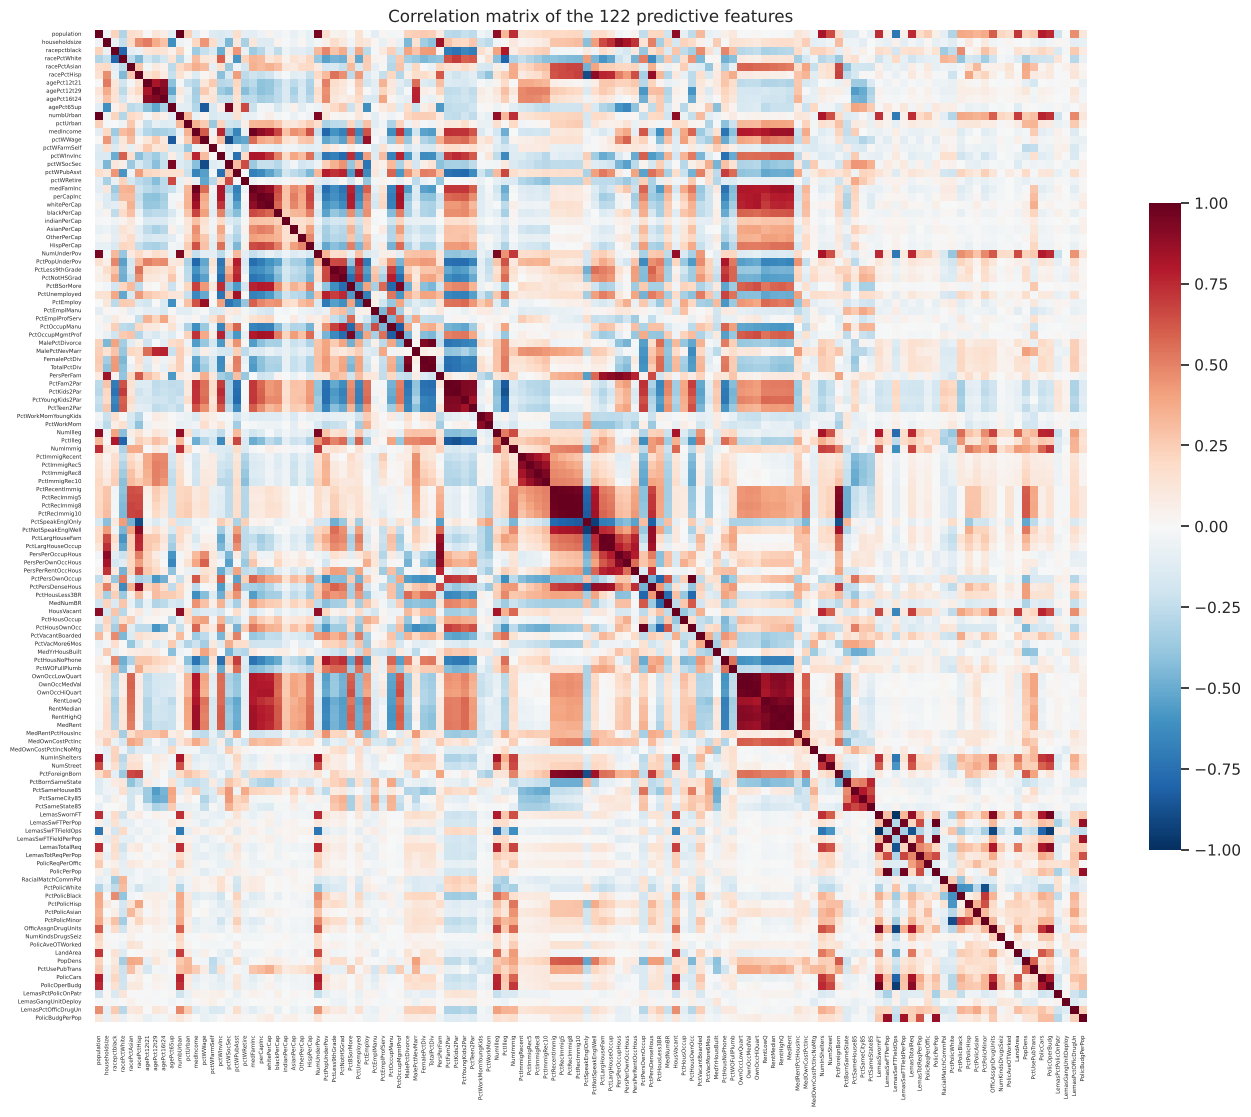

In [14]:
corr = X_all.corr()
fig, ax = plt.subplots(figsize=(16, 14))
sns.heatmap(corr, cmap='RdBu_r', center=0, vmin=-1, vmax=1, square=True,
            xticklabels=True, yticklabels=True, cbar_kws={'shrink': 0.6}, ax=ax)
ax.tick_params(labelsize=4)
ax.set_title('Correlation matrix of the 122 predictive features')
plt.show()

In [15]:
# Summary of the matrix: strongest feature pairs and features most correlated with the target
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().dropna()
print('Feature pairs with |r| > 0.9:', int((upper.abs() > 0.9).sum()), 'of', len(upper))
print('\nTop 10 most correlated feature pairs:')
print(upper.reindex(upper.abs().sort_values(ascending=False).index).head(10).round(3).to_string())
print('\nTop 10 features by |correlation| with ViolentCrimesPerPop:')
ct = X_all.corrwith(pd.concat([y_train, y_test]))# ct: correlation of each feature with the target
print(ct.reindex(ct.abs().sort_values(ascending=False).index).head(10).round(3).to_string())

Feature pairs with |r| > 0.9: 58 of 7381

Top 10 most correlated feature pairs:
LemasSwFTPerPop  PolicPerPop          1.000
PctRecImmig8     PctRecImmig10        0.996
OwnOccLowQuart   OwnOccMedVal         0.994
PctRecImmig5     PctRecImmig8         0.993
population       numbUrban            0.993
LemasSwornFT     LemasSwFTFieldOps   -0.992
OwnOccMedVal     OwnOccHiQuart        0.991
PctRecentImmig   PctRecImmig5         0.989
RentMedian       MedRent              0.989
PctRecImmig5     PctRecImmig10        0.986

Top 10 features by |correlation| with ViolentCrimesPerPop:
PctKids2Par        -0.738
PctIlleg            0.738
PctFam2Par         -0.707
racePctWhite       -0.685
PctYoungKids2Par   -0.666
PctTeen2Par        -0.662
racepctblack        0.631
pctWInvInc         -0.576
pctWPubAsst         0.575
FemalePctDiv        0.556


**Reading the correlation matrix.** Many attributes are highly correlated: there are 58 pairs with $|r| > 0.9$. Such attributes can be grouped together into those measuring almost the same thing, such as `population` and `numbUrban` (0.993), recent immigration (`PctRecImmig5/8/10`, approximately 0.99), the value quartiles of owner-occupied housing and the rent measures. `LemasSwFTPerPop` and `PolicPerPop` are essentially identical (1.000). Multicollinearity is so high that least squares coefficient estimates become unstable, and this is the main reason for using ridge, LASSO and PCR techniques. Attributes most correlated with the target are family structure attributes (`PctKids2Par` −0.74, `PctIlleg` +0.74, `PctFam2Par` −0.71).

## 2(d) Coefficient of variation for each feature

The coefficient of variation $CV = s/m$ gives us a measure of the dispersion of a feature relative to its mean. Since the coefficient of variation is dimensionless,
it allows us to compare features with differing units. A small mean makes the CV large, so skewed features that have most of their values near zero tend to have the highest CV.

In [16]:
# CV = s / m, with s the sample standard deviation (ddof = 1) and m the sample mean
cv_table = pd.DataFrame({'mean': X_all.mean(), 'std': X_all.std(ddof=1)})
cv_table['CV'] = cv_table['std'] / cv_table['mean']
cv_table = cv_table.sort_values('CV', ascending=False)
print('Mean, standard deviation and CV of all 122 features, sorted by CV (read down each column):')
# Two side-by-side columns of (feature, mean, std, CV) to keep the output short
rows = [f'{f:<21s}{m:7.3f}{s:7.3f}{v:7.3f}' for f, (m, s, v) in cv_table.round(3).iterrows()]
half = int(np.ceil(len(rows) / 2))
header = f"{'feature':<21s}{'mean':>7s}{'std':>7s}{'CV':>7s}"
print(header + '   ' + header)
for r in range(half):
    print(rows[r] + ('   ' + rows[r + half] if r + half < len(rows) else ''))

Mean, standard deviation and CV of all 122 features, sorted by CV (read down each column):
feature                 mean    std     CV   feature                 mean    std     CV
PctPolicAsian          0.018  0.100  5.448   PctEmplManu            0.396  0.202  0.511
NumStreet              0.023  0.100  4.408   PctOccupManu           0.391  0.199  0.508
NumInShelters          0.029  0.103  3.485   whitePerCap            0.368  0.187  0.508
NumIlleg               0.036  0.109  2.994   PctImmigRec8           0.399  0.201  0.505
NumImmig               0.030  0.087  2.900   agePct16t24            0.336  0.167  0.495
LemasPctOfficDrugUn    0.094  0.240  2.555   MedOwnCostPctIncNoMtg  0.404  0.193  0.477
NumUnderPov            0.056  0.128  2.305   HispPerCap             0.386  0.183  0.474
population             0.058  0.127  2.204   MedYrHousBuilt         0.494  0.232  0.470
LemasSwornFT           0.028  0.058  2.081   PersPerRentOccHous     0.404  0.189  0.468
numbUrban              0.064 

## 2(e) The $\lfloor\sqrt{128}\rfloor$ features with the highest CV

In [17]:
k = int(np.floor(np.sqrt(128)))# k: number of features to pick, floor(sqrt(128)) = 11
top_cv = list(cv_table.index[:k])# top_cv: names of the k features with the highest CV (cv_table is sorted by CV)
print(f'floor(sqrt(128)) = {k}')
print('Features with the highest CV:', top_cv)

floor(sqrt(128)) = 11
Features with the highest CV: ['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


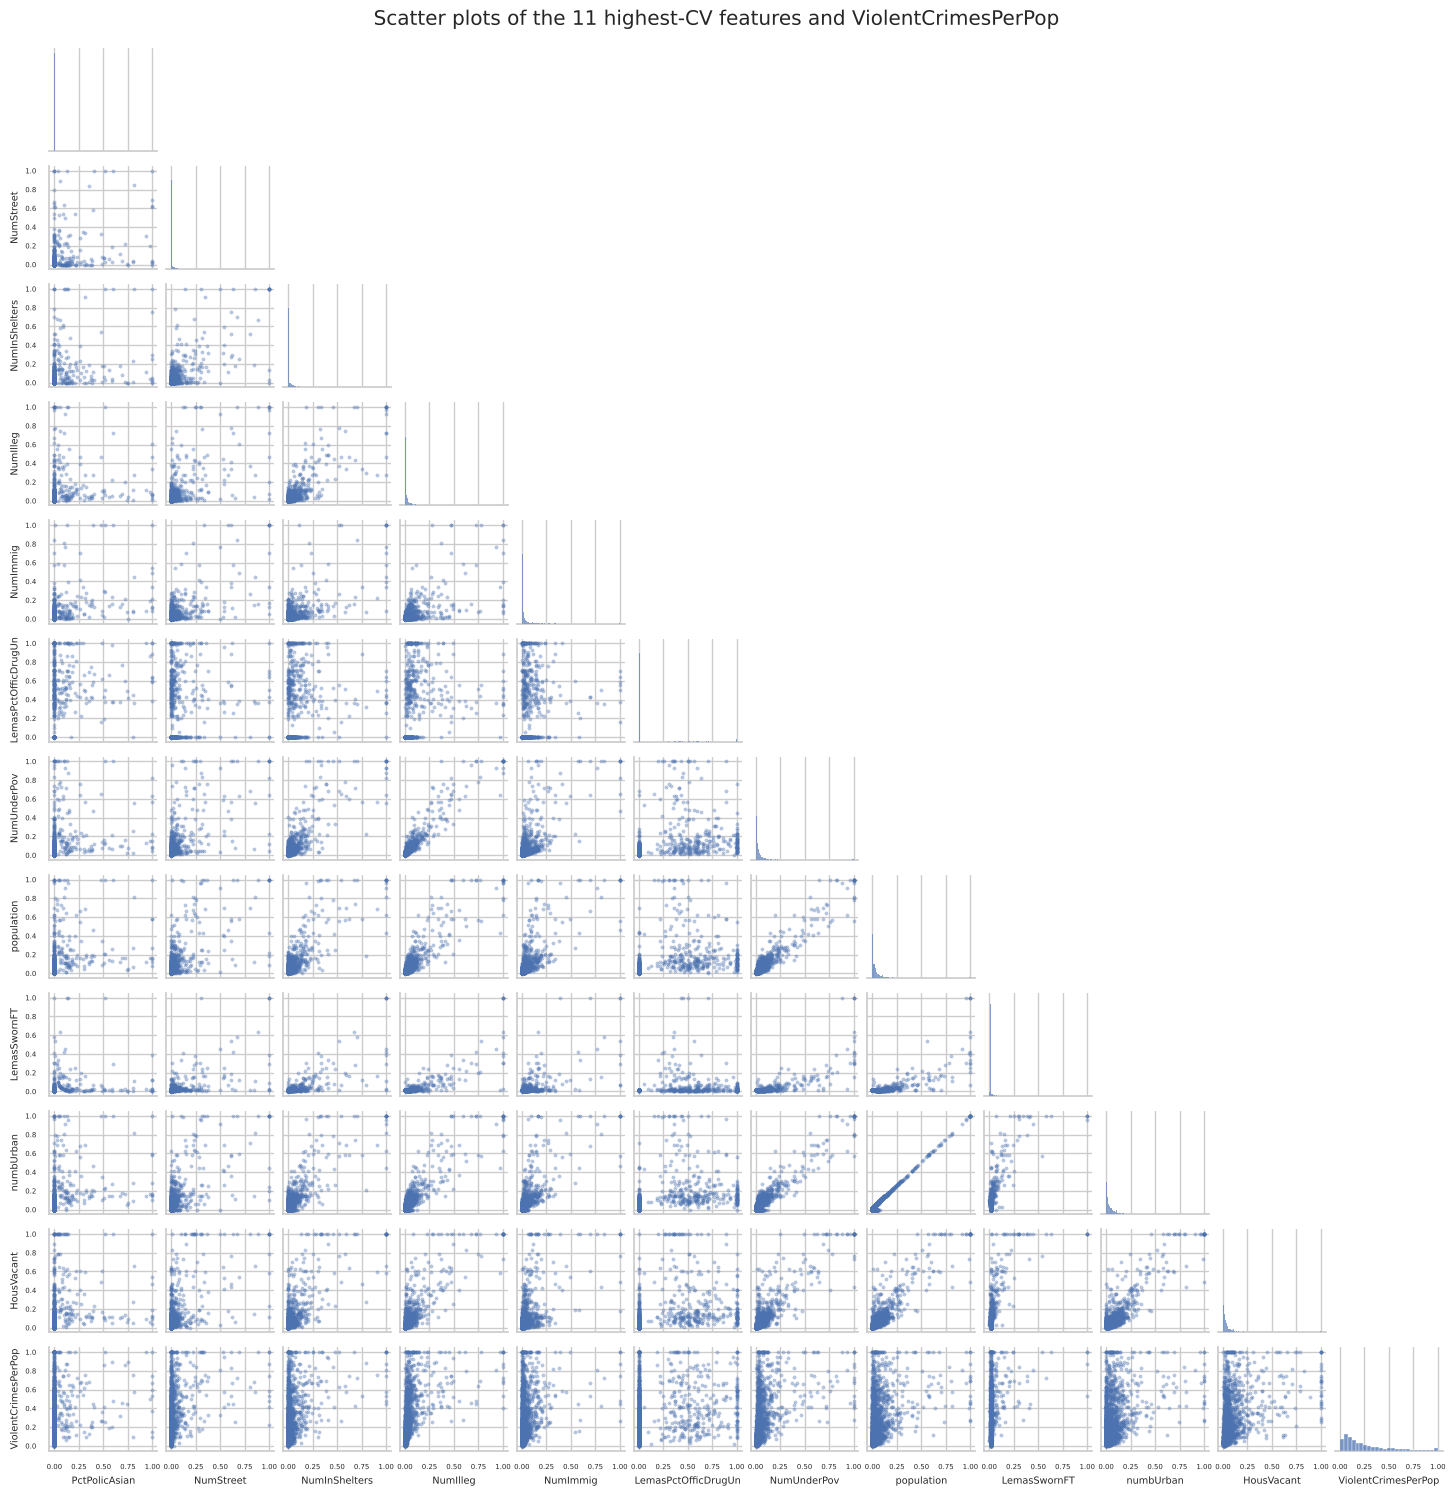

In [18]:
# Scatter plot matrix of the selected features and the target
pp = X_all[top_cv].copy()
pp[target] = pd.concat([y_train, y_test])
g = sns.pairplot(pp, corner=True, plot_kws={'s': 6, 'alpha': 0.4, 'edgecolor': None}, diag_kind='hist', height=1.25)
g.figure.suptitle('Scatter plots of the 11 highest-CV features and ViolentCrimesPerPop', y=1.01)
for ax in g.axes.flat:
    if ax is not None:
        ax.xaxis.label.set_size(7); ax.yaxis.label.set_size(7); ax.tick_params(labelsize=5)
plt.show()

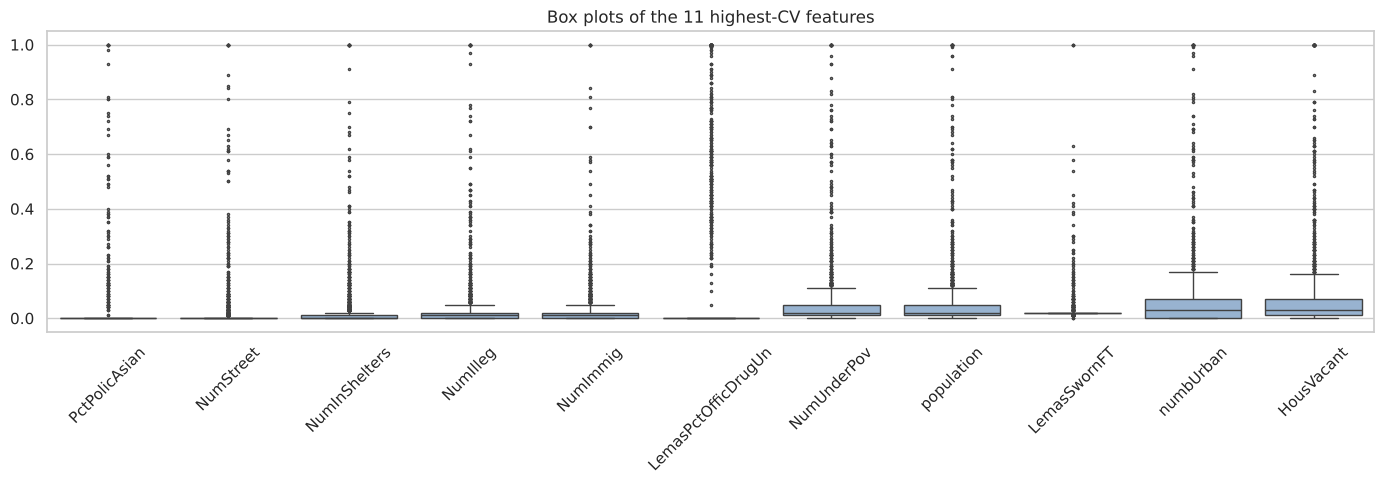

In [19]:
# Box plots of the selected features
fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=X_all[top_cv], ax=ax, color='#8fb3d9', flierprops={'marker': '.', 'markersize': 3})
ax.set_title('Box plots of the 11 highest-CV features')
ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

**Can we draw conclusions about significance from the scatter plots? No.**
- **Scatter plots depict marginal and pairwise relationships**. The importance of the feature in regression depends on the contribution to the model given the existence of the other features. Formal modeling and tests like the coefficient t-test, or cross-validation, are needed. The lower part of the scatter plot matrix shows weak positive relationships with considerable vertical spread (such as the case with NumIlleg and NumUnderPov). The correlation with the response variable is from 0.20 to 0.47 and comes largely from a small number of extreme communities.
- **A high coefficient of variation (CV) does not imply an important feature**. Most of these features are counts: NumStreet, NumIlleg, NumImmig, NumUnderPov, population, numbUrban, HousVacant. They are all skewed: most communities have values close to zero, and only some big cities have values close to 1.0. The high CVs come from the small mean values. Features that are highly correlated with the response variable (PctKids2Par and PctIlleg) are not among the 11 highest-CV features.
- **A number of the features display redundancy**. Population and numbUrban display near-linear correlation, while NumUnderPov and NumIlleg both rise closely with population, implying overlapping information.

- **Imputation affects the following features**: PctPolicAsian, LemasPctOfficDrugUn, and LemasSwornFT, all of which have 84% of data imputed. As a result, most of their values lie at the median, which is shown by the presence of spikes in the histograms. The coefficient of variation for these features is, to some extent, an outcome of the imputation process.

The box plots confirm these observations, since medians are close to zero, while there are long upper tails and many outliers.


## 2(f) Linear model with least squares

**Error metrics used from here on.** The test **MSE** (mean squared error) is the average squared prediction
error on the 499 test communities, $\frac{1}{n}\sum_i (y_i - \hat y_i)^2$. **RMSE** is its square root, in the
same units as the target. **R²** is the share of the variance in the target that the model explains, relative to
always predicting the mean: $R^2 = 0$ means no better than the mean, and $R^2 = 1$ means perfect predictions.
Lower MSE and higher R² are better.

Least squares chooses the coefficients that minimize the residual sum of squares $\sum_i (y_i - \beta_0 - \sum_j \beta_j x_{ij})^2$ on the training set.

In [20]:
results = {}# results: test MSE of each model, collected for the final summary table
ols = LinearRegression().fit(X_train, y_train)# ols: least-squares model fitted on the training set
mse_ols = mean_squared_error(y_test, ols.predict(X_test))
results['Least squares'] = mse_ols
print(f'Least squares: test MSE = {mse_ols:.5f}   test R2 = {r2_score(y_test, ols.predict(X_test)):.4f}')

Least squares: test MSE = 0.01797   test R2 = 0.6222


## 2(g) Ridge regression with λ chosen by cross-validation

Ridge regression adds the penalty $\lambda\sum_j \beta_j^2$ to the loss. It shrinks all coefficients
toward zero but never sets any of them exactly to zero, which stabilizes the fit when features are strongly
correlated. λ is chosen by 10-fold cross-validation over 200 values between $10^{-4}$ and $10^4$ (scikit-learn
calls λ `alpha`).

In [21]:
kf = KFold(n_splits=10, shuffle=True, random_state=SEED)# kf: 10-fold CV splitter, reused for every model below
ridge = RidgeCV(alphas=np.logspace(-4, 4, 200), cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)# ridge: picks the lambda with the lowest CV MSE from 200 values, then refits on the training set
mse_ridge = mean_squared_error(y_test, ridge.predict(X_test))# mse_ridge: its test MSE
results['Ridge'] = mse_ridge
print(f'Chosen lambda = {ridge.alpha_:.4f}')# ridge.alpha_ is the chosen lambda (scikit-learn calls it alpha)
print(f'Ridge: test MSE = {mse_ridge:.5f}   test R2 = {r2_score(y_test, ridge.predict(X_test)):.4f}')

Chosen lambda = 2.1964
Ridge: test MSE = 0.01752   test R2 = 0.6315


## 2(h) LASSO with λ chosen by cross-validation, raw and standardized features

The LASSO regression adds the penalty $\lambda\sum_j|\beta_j|$ to the least-squares loss. The absolute value in the penalty introduces a kink at zero, which enables the LASSO to set some coefficients exactly to zero. The value of λ in LASSO is chosen by 10-fold cross validation on 200 values between [$10^{-6}$, 1]. It should be noted that the LASSO in scikit-learn scales the squared error term by 1/(2n), so its λ values are not on the same scale as ridge’s.

In [22]:
# (1) Features as given (already normalized to [0, 1] in the data set)
lasso = LassoCV(alphas=np.logspace(-6, 0, 200), cv=kf, random_state=SEED, max_iter=50000).fit(X_train, y_train)
mse_lasso = mean_squared_error(y_test, lasso.predict(X_test))
sel = pd.Series(lasso.coef_, index=feat_cc)
sel = sel[sel != 0].sort_values(key=abs, ascending=False)
results['LASSO'] = mse_lasso
print(f'Chosen lambda = {lasso.alpha_:.6f}')
print(f'LASSO: test MSE = {mse_lasso:.5f}   test R2 = {r2_score(y_test, lasso.predict(X_test)):.4f}')
print(f'\n{len(sel)} variables selected (non-zero coefficients):')
print_columns(sel, ncols=3)

Chosen lambda = 0.000085
LASSO: test MSE = 0.01768   test R2 = 0.6281

79 variables selected (non-zero coefficients):
agePct12t29             -0.3150   LemasSwFTFieldPerPop     0.0803   PctWOFullPlumb          -0.0274
racepctblack             0.2696   whitePerCap             -0.0775   LemasTotalReq           -0.0267
PctPersDenseHous         0.2361   NumInShelters            0.0761   PctSameCity85            0.0261
PctKids2Par             -0.2012   PctVacantBoarded         0.0759   HispPerCap               0.0259
MedRent                  0.1820   PctHousLess3BR           0.0748   PctLess9thGrade         -0.0250
PctEmploy                0.1718   PctPersOwnOccup         -0.0731   OtherPerCap              0.0250
RentLowQ                -0.1704   pctWSocSec               0.0691   PctPolicAsian            0.0243
MalePctNevMarr           0.1686   PctVacMore6Mos          -0.0658   blackPerCap             -0.0242
NumStreet                0.1632   PctForeignBorn           0.0621   PctPolicBlack 

In [23]:
# (2) Standardized features: the scaler is fitted inside the pipeline, on training folds only
lasso_std = Pipeline([('scale', StandardScaler()),
                      ('lasso', LassoCV(alphas=np.logspace(-6, 0, 200), cv=kf, random_state=SEED, max_iter=50000))]).fit(X_train, y_train)
mse_lasso_std = mean_squared_error(y_test, lasso_std.predict(X_test))
l2 = lasso_std.named_steps['lasso']
sel_std = pd.Series(l2.coef_, index=feat_cc)
sel_std = sel_std[sel_std != 0].sort_values(key=abs, ascending=False)
results['LASSO (standardized)'] = mse_lasso_std
print(f'Chosen lambda = {l2.alpha_:.6f}')
print(f'LASSO (standardized): test MSE = {mse_lasso_std:.5f}   test R2 = {r2_score(y_test, lasso_std.predict(X_test)):.4f}')
print(f'\n{len(sel_std)} variables selected (non-zero coefficients):')
print_columns(sel_std, ncols=3)

Chosen lambda = 0.000637
LASSO (standardized): test MSE = 0.01772   test R2 = 0.6274

76 variables selected (non-zero coefficients):
racepctblack             0.0680   PctPersOwnOccup         -0.0114   blackPerCap             -0.0039
PctPersDenseHous         0.0432   NumImmig                -0.0113   MedOwnCostPctInc        -0.0036
agePct12t29             -0.0430   PctHousLess3BR           0.0112   PctHousNoPhone           0.0035
PctKids2Par             -0.0406   PctVacMore6Mos          -0.0110   PopDens                  0.0035
RentLowQ                -0.0307   pctWSocSec               0.0103   PctSameCity85            0.0035
MedRent                  0.0303   NumIlleg                -0.0102   NumKindsDrugsSeiz       -0.0035
PctPopUnderPov          -0.0293   PctUsePubTrans          -0.0097   PctLess9thGrade         -0.0034
PctEmploy                0.0250   PolicReqPerOffic         0.0096   PctPolicBlack           -0.0033
MalePctNevMarr           0.0245   whitePerCap             -0.0096  

In [24]:
# Comparison of the two LASSO fits
both = sorted(set(sel.index) & set(sel_std.index))
print(f'Selected: raw = {len(sel)}, standardized = {len(sel_std)}, in both = {len(both)}')
print(f'Test MSE: raw = {mse_lasso:.5f}, standardized = {mse_lasso_std:.5f}')

Selected: raw = 79, standardized = 76, in both = 75
Test MSE: raw = 0.01768, standardized = 0.01772


**Comparison.**

| LASSO fit | Chosen λ | Variables selected | Test MSE |
|---|---|---|---|
| Features as given | 0.000085 | 79 of 122 | 0.01768 |
| Standardized features | 0.000637 | 76 of 122 | 0.01772 |

The selected variables are shown in the preceding two outputs in the order of the size of their coefficients. Both fitted models perform almost identically; their test errors differ only by about 0.2%, and 75 variables are selected in common. This is not surprising since the variables are already scaled to the [0, 1] range (see footnote 4). Standardizing simply adjusts the scale of each variable by dividing it by its standard deviation, which varies between about 0.05 and 0.44. Thus, this does not change the general structure of the model, but the penalty imposed on each coefficient is somewhat different. The selected regularization parameters, λ, are quite different since the coefficients of the two fits operate on different scales. Both λs are small, meaning that the penalty is modest. LASSO removes about one-third of the variables and gives a slightly lower test error than ordinary least squares (0.01797) but a slightly higher test error than ridge regression (0.01752).

## 2(i) Principal components regression (PCR), M chosen by cross-validation

PCR standardizes the features, reduces them to their first M principal components (which are the directions of maximal variance) and applies least-squares regression to those components. The number of components $M$ is chosen using 10-fold cross validation for $M = 1, \dots, 122$. The scaler and the PCA model are fit anew in each training fold.

Chosen M = 97
PCR: test MSE = 0.01837   test R2 = 0.6138


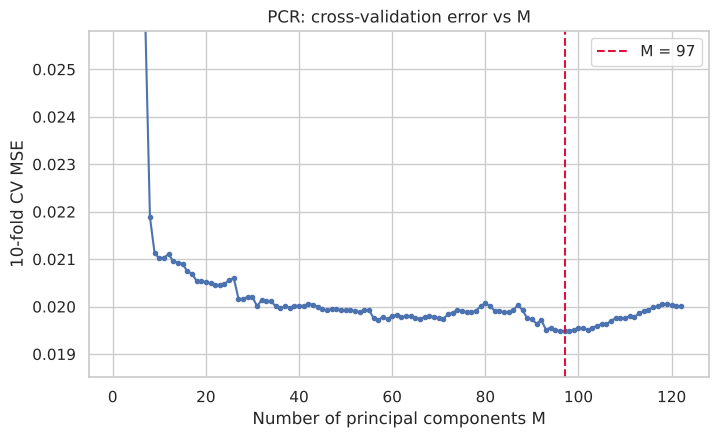

In [25]:
pcr = Pipeline([('scale', StandardScaler()), ('pca', PCA(random_state=SEED)), ('ols', LinearRegression())])# pcr: standardize -> PCA -> least squares
grid_pcr = GridSearchCV(pcr, {'pca__n_components': list(range(1, len(feat_cc) + 1))},# grid_pcr: tries M = 1..122 with 10-fold CV
                        cv=kf, scoring='neg_mean_squared_error').fit(X_train, y_train)
M = grid_pcr.best_params_['pca__n_components']# M: number of components with the lowest CV MSE
mse_pcr = mean_squared_error(y_test, grid_pcr.predict(X_test))
results['PCR'] = mse_pcr
print(f'Chosen M = {M}')
print(f'PCR: test MSE = {mse_pcr:.5f}   test R2 = {r2_score(y_test, grid_pcr.predict(X_test)):.4f}')
cvm = -grid_pcr.cv_results_['mean_test_score']# cvm: CV MSE for each M
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(feat_cc) + 1), cvm, marker='.')
ax.axvline(M, color='crimson', ls='--', label=f'M = {M}')
ax.set_xlabel('Number of principal components M'); ax.set_ylabel('10-fold CV MSE')
ax.set_ylim(cvm.min() * 0.95, np.percentile(cvm, 95))
ax.set_title('PCR: cross-validation error vs M'); ax.legend()
plt.show()

**Result.** Cross-validation has selected M = 97 as the number of components, resulting in a test MSE equal to 0.01837, which is the largest among all the models analyzed. The cross-validation curve decreases steeply in the first 10 components and remains pretty flat from about 30 components onwards, indicating that M = 97 is better than smaller models only by a small margin. PCR chooses the directions that capture the largest amount of variance without taking into account the target. Thus, a much greater number of components is necessary to find out the most important directions for crimes, which means that PCR offers little in terms of dimensionality reduction in this model.

## 2(j) L1-penalized gradient boosting tree (XGBoost), α chosen by cross-validation

**Gradient boosting.** In gradient boosting, trees are built one at a time. Each new tree tries to correct the mistakes of the
previous ones. In particular, XGBoost builds the model as a sum of many shallow trees: each
new tree is fitted to the residuals (the errors) of the trees built so far.

XGBoost includes an L1 penalty reg_alpha $\alpha\sum_ j |w_j|$ on the leaf weights $w_j$
(the predicted values in the leaves) of every tree. This penalty is added to the squared-error loss.

I perform 10-fold cross-validation to tune $\alpha$ while keeping the other hyperparameters fixed:
* The total number of trees is 500, with maximum depth of 3. Each tree is therefore small
and the entire ensemble is built up slowly.
* The learning rate is 0.05. This means that each tree's contribution is scaled by a factor of 0.05,
so no individual tree has too much influence.
* The sampling parameters subsample, colsample_bytree are set to 0.8. This means that each tree is fitted on a random subset
of 80% of the rows, and 80% of the features. This adds randomness and helps prevent overfitting.

Chosen alpha = 3.1623
XGBoost: test MSE = 0.01590   test R2 = 0.6657


,alpha,cv_mse
0,0.00000,0.01949
1,0.00100,0.01953
2,0.00316,0.01954
3,0.01000,0.01958
4,0.03162,0.01937
5,0.10000,0.01923
6,0.31623,0.01934
7,1.00000,0.01908
8,3.16228,0.01900
9,10.00000,0.02068


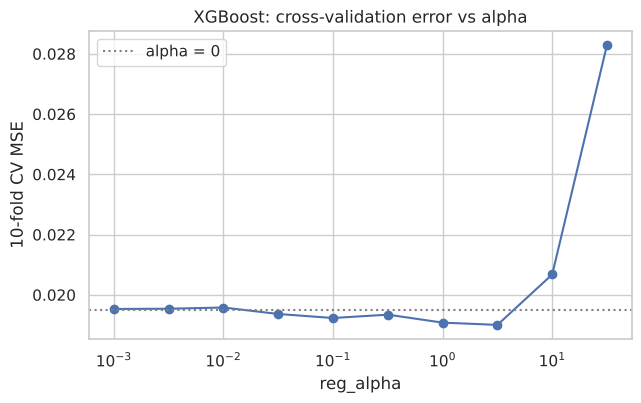

In [26]:
xgb_base = xgb.XGBRegressor(objective='reg:squarederror', n_estimators=500, learning_rate=0.05, max_depth=3,
                            subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)# xgb_base: boosted-tree model with fixed hyperparameters
alpha_grid = [0] + list(np.logspace(-3, 1.5, 10))# alpha_grid: candidate L1 penalties (0, then 0.001 to about 31.6)
grid_xgb = GridSearchCV(xgb_base, {'reg_alpha': alpha_grid}, cv=kf,
                        scoring='neg_mean_squared_error').fit(X_train, y_train)# grid_xgb: picks alpha by 10-fold CV
best_alpha = grid_xgb.best_params_['reg_alpha']# best_alpha: alpha with the lowest CV MSE
mse_xgb = mean_squared_error(y_test, grid_xgb.predict(X_test))
results['XGBoost (L1)'] = mse_xgb
print(f'Chosen alpha = {best_alpha:.4f}')
print(f'XGBoost: test MSE = {mse_xgb:.5f}   test R2 = {r2_score(y_test, grid_xgb.predict(X_test)):.4f}')
cvx = pd.DataFrame({'alpha': alpha_grid, 'cv_mse': -grid_xgb.cv_results_['mean_test_score']}) # cvx: CV MSE for each alpha
display(cvx.round(5))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(cvx['alpha'][1:], cvx['cv_mse'][1:], marker='o')
ax.axhline(cvx['cv_mse'][0], color='grey', ls=':', label='alpha = 0')
ax.set_xscale('log'); ax.set_xlabel('reg_alpha'); ax.set_ylabel('10-fold CV MSE')
ax.set_title('XGBoost: cross-validation error vs alpha'); ax.legend()
plt.show()

**Result.** Cross-validation selects $\alpha = 3.16$. Its test MSE is 0.01590, which is the lowest MSE of any model considered. Moderate L1 regularization reduces the CV error from 0.01949 (α = 0) to 0.01900, but large enough values ($\alpha \geq 10$) overshrink the leaf weights and cause the model to underfit. Boosted trees are also able to account for nonlinearities and interactions between features that the linear models are not, which explains some of the difference in error.

**Note on the method.** The question describes a tree-based model with an L1-regularized regression fit in each node. XGBoost, the tool suggested in the question, implements the L1 penalty in a different way: **reg_alpha** directly penalizes the leaf weights of each regression tree, rather than fitting a LASSO model within each node. Both serve a similar purpose: shrinking the model toward simpler fits.

## Summary of test errors

In [27]:
summary = pd.DataFrame({'test MSE': results}).sort_values('test MSE')
summary['test RMSE'] = np.sqrt(summary['test MSE'])
summary.round(5)

,test MSE,test RMSE
XGBoost (L1),0.01590,0.12608
Ridge,0.01752,0.13237
LASSO,0.01768,0.13298
LASSO (standardized),0.01772,0.13312
Least squares,0.01797,0.13404
PCR,0.01837,0.13552


**Conclusion.** Out of all the models, the L1-penalized XGBoost model has the least amount of test error, with a mean square error (MSE) of 0.01590 and a test $R^2$ value of 0.67. When looking at linear models, ridge regression is considered the best (with a test MSE of 0.01752), followed by LASSO (0.01768 with the features as given and 0.01772 with standardized features) and least squares regression (with a test MSE of 0.01797) and PCR (with a test MSE of 0.01837). All the linear models are within about 5% of each other: ridge and LASSO improve slightly on least squares because the features are highly correlated, but the training set (1495 rows for 122 features) is large enough that least squares does not overfit badly.